# Stage 4 — PAQFE Encoding + PAQFE-QML Training

**Run this as a new, separate Colab notebook** (not appended to `Stage3_PCIF.ipynb` or
`Standard_QML.ipynb`). Reason: Colab's `pcif/` files from Stage 3 only exist inside that
session's disk — they don't carry over to a new notebook. So this notebook **rebuilds the
(corrected) `pcif` package from scratch** in its own first section, then adds the new `paqfe`
package on top. Everything is self-contained — just upload the dataset when prompted and run
top to bottom.

This notebook produces the **PAQFE-QML** result, directly comparable to your existing:

| Model | MAE | RMSE | R2 |
|---|---|---|---|
| Random Forest | 134.95 | 189.14 | 0.630 |
| SVR | 220.95 | 250.70 | 0.350 |
| Standard QML | 207.87 | 260.50 | 0.298 |

**What changes vs Standard QML, and what stays identical (per your proposal's core principle):**
- **Changes:** feature *order* (grouped into contiguous qubit blocks instead of the flat feature
  order) + an extra **physics-informed entangling layer** before the variational circuit, wiring
  together the descriptor pairs Stage 3 confirmed are strongly related (`delta`↔`Omega`,
  `xAl`↔`VEC`, `|dHmix|`↔`Omega`).
- **Stays identical:** qubit count (10), the `StronglyEntanglingLayers` variational backbone
  (depth 3), the readout (PauliZ expectations → linear layer), training procedure, and both
  evaluation protocols (observation-level split, composition-level GroupKFold). Only the
  representation/encoding stage differs, as your methodology requires.

In [1]:
# ============================================================
# 0. Install dependencies
# ============================================================
!pip install -q pennylane pennylane-lightning torch pandas openpyxl scikit-learn matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 5.0 MB/s eta 0:00:00


In [2]:
# ============================================================
# 1. Imports & global config
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import pennylane as qml

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

torch.set_default_dtype(torch.float64)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)


## 2. Rebuild `pcif` (Stage 3, corrected version)

Same as your Stage 3 notebook, including the `pandas` import fix and the `abs_dHmix` correction
you already confirmed (`delta`↔`Omega` r=-0.993, `abs_dHmix`↔`Omega` r=-0.962, `xAl`↔`VEC`
r=-0.934 — all AGREE).

In [3]:
!mkdir -p pcif
!touch pcif/__init__.py


In [4]:
%%writefile pcif/descriptor_groups.py
"""Physics-aware descriptor grouping for PAQFE (Stage 3: PCIF)."""

COMPOSITION_GROUP = ["xAl", "VEC", "dchi"]                    # G_c
THERMODYNAMIC_GROUP = ["dHmix", "dSmix", "Omega", "Mean_Tm"]  # G_t
STRUCTURAL_GROUP = ["delta"]                                   # G_s
CONTEXT_GROUP = ["Temperature_C", "log10_Strain_rate"]         # C

ALL_GROUPS = {
    "composition": COMPOSITION_GROUP,
    "thermodynamic": THERMODYNAMIC_GROUP,
    "structural": STRUCTURAL_GROUP,
}

FEATURES = (
    COMPOSITION_GROUP + THERMODYNAMIC_GROUP + STRUCTURAL_GROUP + CONTEXT_GROUP
)
TARGET = "UTS_MPa"


def get_group_arrays(df):
    return {
        "composition": df[COMPOSITION_GROUP].copy(),
        "thermodynamic": df[THERMODYNAMIC_GROUP].copy(),
        "structural": df[STRUCTURAL_GROUP].copy(),
        "context": df[CONTEXT_GROUP].copy(),
    }


def group_sizes():
    sizes = {name: len(cols) for name, cols in ALL_GROUPS.items()}
    sizes["context"] = len(CONTEXT_GROUP)
    return sizes


Writing pcif/descriptor_groups.py


In [5]:
%%writefile pcif/relationship_rules.py
"""Documented + dataset-confirmed relationships between HEA descriptors (Stage 3: PCIF)."""

RELATIONSHIP_RULES = [
    {
        "pair": ("delta", "Omega"),
        "expected_sign": "negative",
        "confirmed_r": -0.993,
        "reason": "Yang & Zhang Omega-delta criterion.",
    },
    {
        "pair": ("abs_dHmix", "Omega"),
        "expected_sign": "negative",
        "confirmed_r": -0.962,
        "reason": "Omega = Tm * dSmix / |dHmix|; checked against magnitude of dHmix.",
    },
    {
        "pair": ("xAl", "VEC"),
        "expected_sign": "negative",
        "confirmed_r": -0.934,
        "reason": "Al contributes fewer valence electrons than Co/Cr/Fe/Ni in this system.",
    },
]


Writing pcif/relationship_rules.py


In [6]:
from pcif import descriptor_groups as dg
from pcif import relationship_rules as rr

print("Group sizes:", dg.group_sizes())
print("Confirmed relationships:", [r["pair"] for r in rr.RELATIONSHIP_RULES])


Group sizes: {'composition': 3, 'thermodynamic': 4, 'structural': 1, 'context': 2}
Confirmed relationships: [('delta', 'Omega'), ('abs_dHmix', 'Omega'), ('xAl', 'VEC')]


## 3. `paqfe` package — Stage 4

### `paqfe/encoding.py`
Reorders the 10 features into **contiguous qubit blocks by physical group** instead of the flat
order used in Standard QML. Qubit allocation:

| Qubits | Group | Descriptors |
|---|---|---|
| 0–2 | composition (`G_c`) | xAl, VEC, dchi |
| 3–6 | thermodynamic (`G_t`) | dHmix, dSmix, Omega, Mean_Tm |
| 7 | structural (`G_s`) | delta |
| 8–9 | context (`C`) | Temperature_C, log10_Strain_rate |

In [7]:
!mkdir -p paqfe


In [8]:
%%writefile paqfe/__init__.py


Writing paqfe/__init__.py


In [9]:
%%writefile paqfe/encoding.py
"""
PAQFE grouped feature ordering (Stage 4).

Reorders the 10 standardized features into contiguous qubit blocks by physical
group, instead of Standard QML's flat/interleaved order. This ordering is what
allows entanglement.py to entangle each physical group locally before any
cross-group entangling happens.
"""

from pcif import descriptor_groups as dg

# Grouped feature order -> qubit index mapping
GROUPED_FEATURE_ORDER = (
    dg.COMPOSITION_GROUP + dg.THERMODYNAMIC_GROUP + dg.STRUCTURAL_GROUP + dg.CONTEXT_GROUP
)

QUBIT_BLOCKS = {
    "composition": list(range(0, 3)),   # xAl, VEC, dchi
    "thermodynamic": list(range(3, 7)), # dHmix, dSmix, Omega, Mean_Tm
    "structural": [7],                   # delta
    "context": [8, 9],                   # Temperature_C, log10_Strain_rate
}

# Index of each descriptor within GROUPED_FEATURE_ORDER (== its qubit index)
FEATURE_TO_QUBIT = {name: i for i, name in enumerate(GROUPED_FEATURE_ORDER)}


def reorder_to_grouped(X_df):
    """
    X_df: dataframe with columns in ANY order, containing all of GROUPED_FEATURE_ORDER.
    Returns a numpy array with columns reordered to GROUPED_FEATURE_ORDER
    (i.e. column i corresponds to qubit i).
    """
    return X_df[GROUPED_FEATURE_ORDER].to_numpy()


Writing paqfe/encoding.py


### `paqfe/adaptive_rotations.py`
A small, fixed, documented rotation-angle scale per descriptor: features involved in a
Stage-3-confirmed strong relationship (|r| > 0.9) get a mild fixed upweight, so the encoding
stage reflects the physically demonstrated groups rather than treating every qubit identically.
This is a **fixed, pre-declared rule based on Stage 3 findings**, not something tuned against
test accuracy — consistent with your proposal's constraint against arbitrary transformations.

In [10]:
%%writefile paqfe/adaptive_rotations.py
"""
Fixed, documented per-feature rotation scaling (Stage 4).

Scale factors are set BEFORE training, based only on Stage 3's confirmed
|correlation| > 0.9 relationships -- not tuned against model accuracy.
"""

from paqfe.encoding import GROUPED_FEATURE_ORDER

# Descriptors involved in a Stage-3-confirmed strong (|r| > 0.9) relationship
STRONG_RELATIONSHIP_DESCRIPTORS = {"delta", "Omega", "xAl", "VEC"}

UPWEIGHT_FACTOR = 1.2   # fixed, documented -- not tuned
DEFAULT_FACTOR = 1.0

ROTATION_SCALE = [
    UPWEIGHT_FACTOR if name in STRONG_RELATIONSHIP_DESCRIPTORS else DEFAULT_FACTOR
    for name in GROUPED_FEATURE_ORDER
]


Writing paqfe/adaptive_rotations.py


### `paqfe/entanglement.py`
Two-stage entangling pattern, applied immediately after angle embedding and BEFORE the shared
`StronglyEntanglingLayers` backbone:

1. **Intra-group entangling** — a ring of CNOTs within each group's own qubits (composition
   block, thermodynamic block; the single structural qubit and 2-qubit context block use a
   simple linear/no-op pattern).
2. **Relationship-informed cross-qubit entangling** — one CNOT per Stage-3-confirmed strong
   relationship, directly wiring `delta`↔`Omega` and `xAl`↔`VEC` (the two confirmed pairs that
   land on different qubits within reach)— since Standard QML's uniform entangler has no
   equivalent physically-motivated structure.

In [11]:
%%writefile paqfe/entanglement.py
"""
Physics-informed entangling layer (Stage 4).

Applied once, right after angle embedding, before the shared StronglyEntanglingLayers
variational backbone (which stays identical to Standard QML).
"""

import pennylane as qml
from paqfe.encoding import QUBIT_BLOCKS, FEATURE_TO_QUBIT


def _ring_entangle(wires):
    if len(wires) < 2:
        return
    for i in range(len(wires)):
        qml.CNOT(wires=[wires[i], wires[(i + 1) % len(wires)]])


def physics_entangling_layer():
    # 1. Intra-group entangling
    _ring_entangle(QUBIT_BLOCKS["composition"])
    _ring_entangle(QUBIT_BLOCKS["thermodynamic"])
    _ring_entangle(QUBIT_BLOCKS["context"])
    # structural group has only 1 qubit -- nothing to entangle internally

    # 2. Relationship-informed cross-qubit entangling
    # (Stage 3 confirmed: delta<->Omega r=-0.993, xAl<->VEC r=-0.934)
    qml.CNOT(wires=[FEATURE_TO_QUBIT["delta"], FEATURE_TO_QUBIT["Omega"]])
    qml.CNOT(wires=[FEATURE_TO_QUBIT["xAl"], FEATURE_TO_QUBIT["VEC"]])


Writing paqfe/entanglement.py


## 4. Quantum circuit + hybrid torch model

Same qubit count (10), same `StronglyEntanglingLayers` depth-3 backbone, and same readout
(PauliZ expectations → `nn.Linear`) as Standard QML — only the encoding stage differs.

In [12]:
from paqfe.encoding import reorder_to_grouped, GROUPED_FEATURE_ORDER
from paqfe.adaptive_rotations import ROTATION_SCALE
from paqfe.entanglement import physics_entangling_layer

N_QUBITS = len(GROUPED_FEATURE_ORDER)  # 10
N_LAYERS = 3

ROTATION_SCALE_T = torch.tensor(ROTATION_SCALE, dtype=torch.float64)

dev = qml.device("lightning.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="adjoint")
def paqfe_circuit(inputs, weights):
    scaled_inputs = inputs * ROTATION_SCALE_T
    qml.templates.AngleEmbedding(scaled_inputs, wires=range(N_QUBITS), rotation="Y")
    physics_entangling_layer()
    qml.templates.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS, n_wires=N_QUBITS)}


def make_paqfe_model(seed):
    torch.manual_seed(seed)
    qlayer = qml.qnn.TorchLayer(paqfe_circuit, weight_shapes)
    model = nn.Sequential(qlayer, nn.Linear(N_QUBITS, 1))
    return model


## 5. Training function

Same structure as Standard QML's `train_standard_qml`, but reorders features into the grouped
qubit order first.

In [13]:
def train_paqfe_qml(
    X_train, y_train, X_test, y_test,
    seed=42, n_epochs=200, lr=0.02, verbose=False
):
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train_s = x_scaler.fit_transform(X_train[GROUPED_FEATURE_ORDER])
    X_test_s = x_scaler.transform(X_test[GROUPED_FEATURE_ORDER])

    y_train_s = y_scaler.fit_transform(np.array(y_train).reshape(-1, 1)).flatten()

    X_train_t = torch.tensor(X_train_s, dtype=torch.float64)
    y_train_t = torch.tensor(y_train_s, dtype=torch.float64).reshape(-1, 1)
    X_test_t = torch.tensor(X_test_s, dtype=torch.float64)

    model = make_paqfe_model(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(n_epochs):
        optimizer.zero_grad()
        preds = model(X_train_t)
        loss = loss_fn(preds, y_train_t)
        loss.backward()
        optimizer.step()

        if verbose and (epoch + 1) % 50 == 0:
            print(f"  epoch {epoch+1}/{n_epochs} -- loss {loss.item():.4f}")

    with torch.no_grad():
        test_preds_s = model(X_test_t).numpy().flatten()

    test_preds = y_scaler.inverse_transform(test_preds_s.reshape(-1, 1)).flatten()

    mae = mean_absolute_error(y_test, test_preds)
    rmse = np.sqrt(mean_squared_error(y_test, test_preds))
    r2 = r2_score(y_test, test_preds)

    return {"MAE": mae, "RMSE": rmse, "R2": r2, "y_pred": test_preds}


## 6. Load dataset

In [14]:
from google.colab import files
uploaded = files.upload()  # choose "PAQFE_UTS_Dataset_Corrected (1).xlsx"

file_path = list(uploaded.keys())[0]
df = pd.read_excel(file_path, sheet_name="B_Model_Ready")

composition_cols = ["Al_norm", "Co_norm", "Cr_norm", "Fe_norm", "Ni_norm"]
df["Composition_Group"] = df[composition_cols].round(3).astype(str).agg("_".join, axis=1)
df["abs_dHmix"] = df["dHmix"].abs()

FEATURES = GROUPED_FEATURE_ORDER
TARGET = "UTS_MPa"

X_all = df[FEATURES].copy()
y_all = df[TARGET].copy()

print("Dataset shape:", df.shape)
print("Feature order (== qubit order):", FEATURES)


Saving PAQFE_UTS_Dataset_Corrected (1).xlsx to PAQFE_UTS_Dataset_Corrected (1).xlsx
Dataset shape: (49, 27)
Feature order (== qubit order): ['xAl', 'VEC', 'dchi', 'dHmix', 'dSmix', 'Omega', 'Mean_Tm', 'delta', 'Temperature_C', 'log10_Strain_rate']


## 7. Observation-level PAQFE-QML

Same split as Standard QML: `train_test_split(..., test_size=0.20, random_state=42)`. Same
5-init-seed repeat protocol for mean±SD.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_SEED
)

N_SEED_REPEATS = 5
obs_repeat_scores = []
obs_last_preds = None

for seed in range(RANDOM_SEED, RANDOM_SEED + N_SEED_REPEATS):
    print(f"\n--- PAQFE-QML observation-level | init seed {seed} ---")
    result = train_paqfe_qml(X_train, y_train, X_test, y_test, seed=seed, n_epochs=200, verbose=True)
    obs_repeat_scores.append({"Seed": seed, "MAE": result["MAE"], "RMSE": result["RMSE"], "R2": result["R2"]})
    if seed == RANDOM_SEED:
        obs_last_preds = result["y_pred"]
    print(f"  MAE={result['MAE']:.4f}  RMSE={result['RMSE']:.4f}  R2={result['R2']:.4f}")

obs_repeat_df = pd.DataFrame(obs_repeat_scores)
obs_repeat_df



--- PAQFE-QML observation-level | init seed 42 ---
  epoch 50/200 -- loss 0.1648
  epoch 100/200 -- loss 0.0495
  epoch 150/200 -- loss 0.0470
  epoch 200/200 -- loss 0.0466
  MAE=226.6666  RMSE=286.0031  R2=0.1543

--- PAQFE-QML observation-level | init seed 43 ---
  epoch 50/200 -- loss 0.1057
  epoch 100/200 -- loss 0.0527
  epoch 150/200 -- loss 0.0498
  epoch 200/200 -- loss 0.0486
  MAE=251.5397  RMSE=319.3405  R2=-0.0544

--- PAQFE-QML observation-level | init seed 44 ---
  epoch 50/200 -- loss 0.2817
  epoch 100/200 -- loss 0.0507
  epoch 150/200 -- loss 0.0474
  epoch 200/200 -- loss 0.0469
  MAE=249.6321  RMSE=321.6176  R2=-0.0695

--- PAQFE-QML observation-level | init seed 45 ---
  epoch 50/200 -- loss 0.1025
  epoch 100/200 -- loss 0.0482
  epoch 150/200 -- loss 0.0476
  epoch 200/200 -- loss 0.0473
  MAE=240.4621  RMSE=306.1492  R2=0.0309

--- PAQFE-QML observation-level | init seed 46 ---
  epoch 50/200 -- loss 0.1559
  epoch 100/200 -- loss 0.0502
  epoch 150/200 -- lo

,Seed,MAE,RMSE,R2
0,42,226.666566,286.003101,0.154288
1,43,251.539701,319.340493,-0.054360
2,44,249.632073,321.617568,-0.069450
3,45,240.462086,306.149189,0.030948
4,46,215.042097,269.713335,0.247882


In [16]:
print("========================================")
print("PAQFE-QML -- OBSERVATION LEVEL (Mean +/- SD)")
print("========================================")
print(f"MAE  : {obs_repeat_df['MAE'].mean():.4f} +/- {obs_repeat_df['MAE'].std():.4f}")
print(f"RMSE : {obs_repeat_df['RMSE'].mean():.4f} +/- {obs_repeat_df['RMSE'].std():.4f}")
print(f"R2   : {obs_repeat_df['R2'].mean():.4f} +/- {obs_repeat_df['R2'].std():.4f}")

print("\nHeadline run (seed=42) -- directly comparable to your existing table:")
print(f"MAE  : {obs_repeat_df.iloc[0]['MAE']:.4f}")
print(f"RMSE : {obs_repeat_df.iloc[0]['RMSE']:.4f}")
print(f"R2   : {obs_repeat_df.iloc[0]['R2']:.4f}")

print("\nFor reference -- Standard QML (already obtained): MAE=207.8663 RMSE=260.4988 R2=0.2984")


PAQFE-QML -- OBSERVATION LEVEL (Mean +/- SD)
MAE  : 236.6685 +/- 15.5831
RMSE : 300.5647 +/- 22.3091
R2   : 0.0619 +/- 0.1368

Headline run (seed=42) -- directly comparable to your existing table:
MAE  : 226.6666
RMSE : 286.0031
R2   : 0.1543

For reference -- Standard QML (already obtained): MAE=207.8663 RMSE=260.4988 R2=0.2984


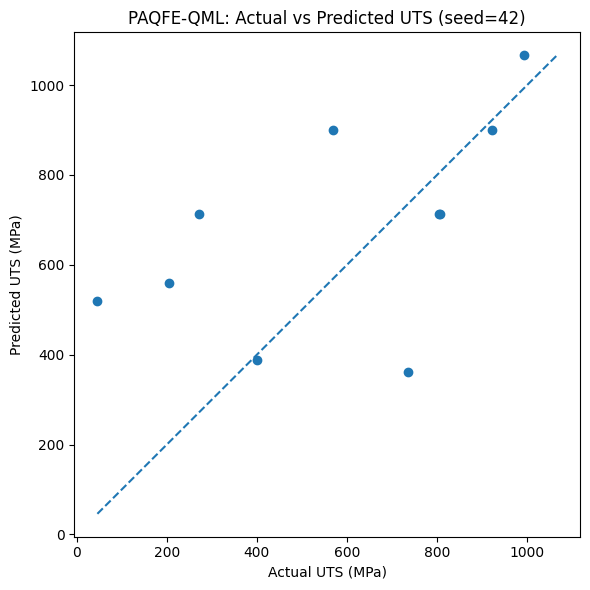

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, obs_last_preds)
min_val = min(y_test.min(), obs_last_preds.min())
max_val = max(y_test.max(), obs_last_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual UTS (MPa)")
plt.ylabel("Predicted UTS (MPa)")
plt.title("PAQFE-QML: Actual vs Predicted UTS (seed=42)")
plt.tight_layout()
plt.show()


## 8. Composition-level PAQFE-QML

Identical protocol to Standard QML: `GroupKFold(n_splits=5)`, 5 repeats, seeds 42-46.

In [18]:
n_repeats = 5
n_splits = 5

paqfe_repeat_scores = []
groups = df["Composition_Group"].copy()

for repeat in range(n_repeats):
    seed = RANDOM_SEED + repeat
    print(f"\n========== REPEAT {repeat + 1} (seed={seed}) ==========")

    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    y_true_all, y_pred_all = [], []

    for fold, (train_idx, test_idx) in enumerate(gkf.split(X_all, y_all, groups), start=1):
        X_train_f = X_all.iloc[train_idx]
        X_test_f = X_all.iloc[test_idx]
        y_train_f = y_all.iloc[train_idx]
        y_test_f = y_all.iloc[test_idx]

        result = train_paqfe_qml(X_train_f, y_train_f, X_test_f, y_test_f, seed=seed, n_epochs=150)

        y_true_all.extend(list(y_test_f))
        y_pred_all.extend(list(result["y_pred"]))

        print(f"Fold {fold} completed")

    mae = mean_absolute_error(y_true_all, y_pred_all)
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    r2 = r2_score(y_true_all, y_pred_all)

    paqfe_repeat_scores.append({"Repeat": repeat + 1, "MAE": mae, "RMSE": rmse, "R2": r2})
    print(f"Repeat {repeat + 1} completed -- MAE={mae:.4f} RMSE={rmse:.4f} R2={r2:.4f}")

paqfe_repeat_results = pd.DataFrame(paqfe_repeat_scores)
paqfe_repeat_results



========== REPEAT 1 (seed=42) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 1 completed -- MAE=235.6697 RMSE=320.0374 R2=0.3437

========== REPEAT 2 (seed=43) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 2 completed -- MAE=208.3803 RMSE=307.9694 R2=0.3922

========== REPEAT 3 (seed=44) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 3 completed -- MAE=266.4506 RMSE=354.5496 R2=0.1945

========== REPEAT 4 (seed=45) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 4 completed -- MAE=175.8364 RMSE=272.1577 R2=0.5254

========== REPEAT 5 (seed=46) ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 5 completed -- MAE=219.0311 RMSE=294.7705 R2=0.4432


,Repeat,MAE,RMSE,R2
0,1,235.669706,320.037403,0.343679
1,2,208.380328,307.969433,0.392243
2,3,266.450602,354.549630,0.194493
3,4,175.836427,272.157665,0.525369
4,5,219.031107,294.770477,0.443221


In [19]:
print("======================================")
print("FINAL COMPOSITION-LEVEL PAQFE-QML")
print("======================================")
print(f"MAE  : {paqfe_repeat_results['MAE'].mean():.4f} +/- {paqfe_repeat_results['MAE'].std():.4f}")
print(f"RMSE : {paqfe_repeat_results['RMSE'].mean():.4f} +/- {paqfe_repeat_results['RMSE'].std():.4f}")
print(f"R2   : {paqfe_repeat_results['R2'].mean():.4f} +/- {paqfe_repeat_results['R2'].std():.4f}")


FINAL COMPOSITION-LEVEL PAQFE-QML
MAE  : 221.0736 +/- 33.4806
RMSE : 309.8969 +/- 30.6328
R2   : 0.3798 +/- 0.1235


## 9. Save results

In [20]:
obs_headline = pd.DataFrame({
    "Model": ["PAQFE-QML"],
    "MAE": [obs_repeat_df.iloc[0]["MAE"]],
    "RMSE": [obs_repeat_df.iloc[0]["RMSE"]],
    "R2": [obs_repeat_df.iloc[0]["R2"]],
})

comp_summary = pd.DataFrame({
    "Model": ["PAQFE-QML"],
    "MAE (Mean)": [paqfe_repeat_results["MAE"].mean()],
    "MAE (SD)": [paqfe_repeat_results["MAE"].std()],
    "RMSE (Mean)": [paqfe_repeat_results["RMSE"].mean()],
    "RMSE (SD)": [paqfe_repeat_results["RMSE"].std()],
    "R2 (Mean)": [paqfe_repeat_results["R2"].mean()],
    "R2 (SD)": [paqfe_repeat_results["R2"].std()],
})

with pd.ExcelWriter("PAQFE_QML_Results.xlsx", engine="openpyxl") as writer:
    obs_headline.to_excel(writer, sheet_name="Observation_Level", index=False)
    obs_repeat_df.to_excel(writer, sheet_name="Observation_Seed_Repeats", index=False)
    comp_summary.to_excel(writer, sheet_name="Composition_Level", index=False)
    paqfe_repeat_results.to_excel(writer, sheet_name="Composition_Repeated_Runs", index=False)

print("Saved: PAQFE_QML_Results.xlsx")

from google.colab import files as colab_files
colab_files.download("PAQFE_QML_Results.xlsx")


Saved: PAQFE_QML_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next: Experiment 8 (physics ablation)

Once you've got these numbers, the next natural step per your proposal is the ablation
(A1 standard / A2 physics-transform only / A3 full PAQFE) to isolate exactly how much of any
improvement comes from grouping+entanglement vs the encoding order alone. Hold off on that until
you've reviewed these PAQFE-QML numbers against Standard QML.